# Bayesian hyperpriors and WoW-neighbourhood concentration

We retain the hierarchical sampling mechanism

$$
\mu_c\overset{\mathrm{iid}}{\sim}P^*,\qquad
x_{c,i}\overset{\mathrm{iid}}{\sim}\mu_c,
$$

but now place a Bayesian hyperprior $\Pi$ on the unknown population measure $P\in\mathcal P(\mathcal P(\mathbb R^2))$. The quantity of interest is the posterior mass of Wasserstein neighbourhoods of the realised truth:

$$
\boxed{\Pi\!\left(\left\{P:
W_{W_2}(P,P^*)<\varepsilon\right\}\mid \mathcal D\right)}.
$$

The prior $\Pi$ itself does not adapt to the data $\mathcal D$. It is the **posterior induced by the hyperprior** that should put increasing mass on WoW-neighbourhoods of $P^*$.

The Bayesian hierarchy is $P\sim\Pi$, $\mu_c\mid P\sim P$, and $x_{ci}\mid\mu_c\sim\mu_c$. In the experiment, the data are generated from one fixed true population $P^*$; inference updates the hyperprior to $\Pi(\cdot\mid\mathcal D)$.

We use the translated-ring family with the same finite base-ring support as in the empirical case. The synthetic model lets us check the Bayesian inference against a known truth.

## Sampling hierarchy

Let $\nu$ be the common centred ring law, and let

$$
\mu_a = (z\mapsto z+(a,0))_\#\nu.
$$

The true population is

$$
P^* = (a\mapsto\mu_a)_\#G^*,
\qquad G^*=\mathrm{Uniform}([-L,L]).
$$

Each class first draws $a_c\sim G^*$, equivalently $\mu_c\sim P^*$, then samples its observations from $\mu_{a_c}$. Candidate centres are represented by midpoint quadrature nodes on $[-L,L]$, for likelihood integration and finite-dimensional posterior approximations.



## Two hyperpriors

1. **Parametric baseline.** The centre weights are an exponential tilt of the uniform weights, $$w_j(\theta)\propto\exp\{\theta(a_j/L)^2\}.$$ The continuous tilt family has truth $\theta^*=0$. The computation represents this family by midpoint quadrature weights; a prior on $\theta$ induces a hyperprior on its discretised population measures.
2. **Finite-support Dirichlet-process approximation.** Put $$w\sim\mathrm{Dirichlet}(\alpha H_1,\ldots,\alpha H_K),\quad P_w=\sum_jw_j\delta_{\mu_{a_j}}.$$ This is a finite-dimensional approximation to a DP hyperprior on the ring-law family. Its grid support approximates the continuous truth and is much richer than the parametric family.

For both models we retain the same generated data. We vary both the number of classes $C$ and observations per class $n$. Increasing $n$ helps identify each sampled class law, whereas increasing $C$ supplies more draws from the population $P^*$.

---

## 1. Imports and configuration

All parameters (ring, centre grid, $C$/$n$ design, $\varepsilon$ balls, both hyperpriors, MCMC settings) are `bayes_*` fields of the shared `Config`; override them in the cell below. The ring is the same finite-support ring as in notebook 01.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import make_config, describe
import utils as U

# ---- Parameters ---------------------------------------------------------------
# Defaults live in config.py.  To deviate in THIS notebook only, list overrides
# below (any Config field), e.g.
#     OVERRIDES = dict(meta_repeats=4, results_root="results_scratch")
OVERRIDES = {}
cfg = make_config(**OVERRIDES)
describe(cfg)

U.apply_style()
print("OT backend:", U.ot_backend())

Using config.py defaults.
OT backend: POT available; SciPy assignment used for equal-weight square problems


In [2]:
ring = U.build_ring(cfg)
C_VALUES, N_VALUES = cfg.bayes_c_values, np.asarray(cfg.bayes_n_values)
print(f"Ring support: {ring.size} atoms; radius={cfg.ring_radius}; radial jitter={cfg.ring_radial_jitter}")
print(f"Centre population: Uniform[-{cfg.centre_limit}, {cfg.centre_limit}] on {cfg.bayes_n_centres} midpoint nodes")
print(f"Settings: C = {C_VALUES[0]}..{C_VALUES[-1]} ({len(C_VALUES)} values), n = {N_VALUES.tolist()}, repetitions = {cfg.bayes_repeats}")
print(f"Finite-DP chain: burn-in={cfg.bayes_dp_burn_in}, draws={cfg.bayes_dp_draws}, thinning={cfg.bayes_dp_thin}")
print(f"Total number of fits: {len(C_VALUES) * len(N_VALUES) * cfg.bayes_repeats}")

Ring support: 2048 atoms; radius=0.7; radial jitter=0.045
Centre population: Uniform[-2.0, 2.0] on 200 midpoint nodes
Settings: C = 50..5000 (100 values), n = [1000], repetitions = 16
Finite-DP chain: burn-in=20, draws=500, thinning=1
Total number of fits: 1600


---

## 2. Generating the hierarchical data

Each observed class law is a translate of this fixed finite-support measure. The centre of each class is sampled i.i.d. from $\mathrm{Unif}([-L,L])$, matching the growing-$C$ experiment of the empirical notebook.

For each repetition, the largest set of centres and within-class observations is generated once. Smaller $(C,n)$ experiments use prefixes, so settings are nested within a repetition. The base ring's radial support is a finite approximation to a ring with radius $R=0.7$ and radial jitter $0.045$; the likelihood below uses the corresponding smooth truncated-Normal radial working density.

Generating ring replicates: 100%|██████████| 16/16 [00:02<00:00,  6.00it/s]


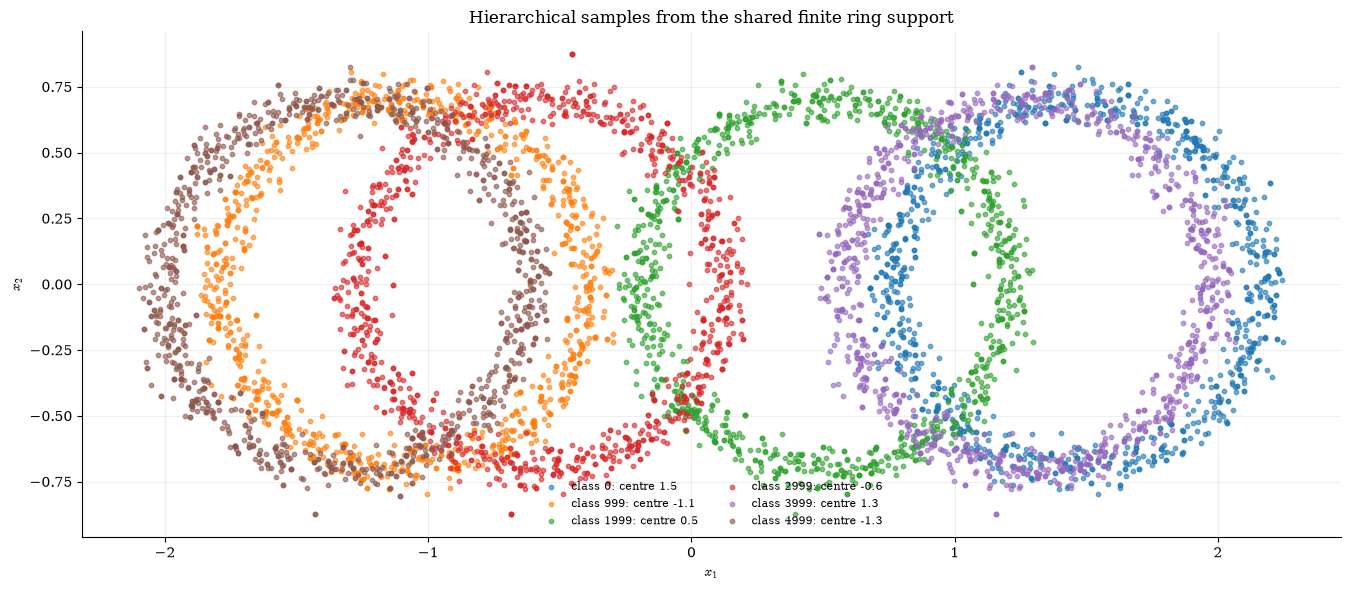

In [3]:
latent_centres_bank, data_bank = U.generate_bayes_replicates(cfg, ring)

fig, ax = plt.subplots(figsize=(20, 6))
max_c = data_bank.shape[1]
for c in np.unique(np.linspace(0, max_c - 1, 6, dtype=int)):
    Xc = data_bank[0, c]
    ax.scatter(Xc[:, 0], Xc[:, 1], s=10, alpha=0.6,
               label=f"class {c}: centre {latent_centres_bank[0, c]:.1f}")
ax.set_aspect("equal")
ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
ax.set_title("Hierarchical samples from the shared finite ring support")
ax.legend(fontsize=8, ncol=2, frameon=False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

---

## 3. Observation likelihood and exact WoW distance

For likelihood evaluation we use the smooth radial working model corresponding to the matched ring radius and jitter: the polar radius has a Normal density truncated to $r>0$, and the angle is uniform. Its density with respect to planar Lebesgue measure is

$$
p(x\mid a)=\frac{1}{2\pi r}\,
\frac{\phi((r-R)/\sigma_r)}{\sigma_r\,\Phi(R/\sigma_r)},
\quad r=\|x-ae_1\|.
$$

For a candidate discrete centre law $G_w=\sum_jw_j\delta_{a_j}$, let $u_j=\sum_{k\leq j}w_k$, $u_0=0$, and $m_j=u_j-u_{j-1}=w_j$. Its quantile is constant at $a_j$ on $[u_{j-1},u_j)$, while the uniform truth has quantile $-L+2Lu$.

$$
W_2^2(G_w,G^*)=\sum_j\left[
 w_j\big(a_j-(-L+2L\bar u_j)\big)^2
 +\frac{(2L)^2w_j^3}{12}
\right],
\qquad \bar u_j=\frac{u_{j-1}+u_j}{2}.
$$

---

## 4. Parametric hyperprior: a posterior over a one-parameter family of populations

The underlying continuous family has density

$$
g_\theta(a)\propto\exp\{\theta(a/L)^2\},\qquad -L\leq a\leq L.
$$

We approximate its integrals by midpoint quadrature on candidate nodes $a_1,\ldots,a_K$, giving

$$
G_\theta^{(K)}=\sum_{j=1}^K w_j(\theta)\delta_{a_j},\qquad
w_j(\theta)=\frac{\exp\{\theta q_j\}}{\sum_\ell\exp\{\theta q_\ell\}},
\qquad q_j=(a_j/L)^2.
$$

The truth is the continuous uniform distribution on $[-L,L]$, corresponding to $\theta^*=0$. A Normal prior is placed on $\theta$ (mean and sd from `bayes_theta_prior_*`, default $-0.8$ and $1.8$). This prior mildly favours central centres; it is not centred at the truth. The induced prior on $P_\theta=(a\mapsto\mu_a)_\#G_\theta$ is our parametric hyperprior $\Pi$.

For a class with observations $D_c$, we integrate out its latent centre:

$$
p(D_c\mid\theta)=\sum_jw_j(\theta)p(D_c\mid a_j).
$$

In [4]:
family = U.build_param_family(cfg)
print(f"Uniform midpoint-grid approximation floor in WoW: {family.grid_floor:.6f}")
print("Parametric prior mass in WoW balls:")
for eps, mass in zip(cfg.bayes_epsilons, family.prior_ball_mass):
    print(f"  epsilon={eps:.2f}: {mass:.4f}")

Uniform midpoint-grid approximation floor in WoW: 0.005774
Parametric prior mass in WoW balls:
  epsilon=0.05: 0.1107
  epsilon=0.10: 0.2159
  epsilon=0.15: 0.3275
  epsilon=0.20: 0.4386
  epsilon=0.25: 0.5387


## 5. Finite-support DP hyperprior

For a more flexible prior, let

$$
w\sim\mathrm{Dirichlet}(\alpha H_1,\ldots,\alpha H_K),
\qquad P_w=\sum_{j=1}^K w_j\delta_{\mu_{a_j}}.
$$

This is a finite-support approximation to a Dirichlet-process hyperprior on the family of ring laws. The base weights $H_j\propto\exp\{-a_j^2/(2s^2)\}$ (with $s=$ `bayes_dp_base_sd`) favour central centres, while the true centre law is continuous uniform.

Introduce a latent centre index $z_c$ for each class. Given the class likelihoods $\ell_{cj}=\log p(D_c\mid a_j)$, a Gibbs sampler alternates

$$
z_c\mid w,D_c\sim\mathrm{Categorical}
\left(\frac{w_j e^{\ell_{cj}}}{\sum_k w_ke^{\ell_{ck}}}\right),
\quad
w\mid z\sim\mathrm{Dirichlet}(\alpha H_j+N_j).
$$

Each posterior draw $w^{(s)}$ gives a grid-supported population $P_{w^{(s)}}$.

In [5]:
dp_prior = U.dp_prior_draws(cfg)
print(f"Numba assignment kernel available: {U.NUMBA_AVAILABLE}")
if not U.NUMBA_AVAILABLE:
    print(f"Numba import unavailable; using NumPy fallback ({U.NUMBA_IMPORT_ERROR})")
print("Finite-DP prior mass in WoW balls:")
for eps, mass in zip(cfg.bayes_epsilons, dp_prior["ball_mass"]):
    print(f"  epsilon={eps:.2f}: {mass:.4f}")

Numba assignment kernel available: True
Finite-DP prior mass in WoW balls:
  epsilon=0.05: 0.0000
  epsilon=0.10: 0.0000
  epsilon=0.15: 0.0000
  epsilon=0.20: 0.0000
  epsilon=0.25: 0.0000


---

## 6. Fit both hyperpriors

For every repetition, $C$ and $n$ we compute the parametric posterior on the $\theta$ grid and draw the finite-DP posterior with the Gibbs sampler.

In [6]:
fits = U.run_bayes_fits(cfg, data_bank, family, U.bayes_dir(cfg))

Bayesian posterior fits: 100%|██████████| 1600/1600 [00:01<00:00, 982.55it/s] 

Posterior fitting complete. Checkpoints are in: /Users/shen/Desktop/L2WDatasets/results/bayes/checkpoints


In [7]:
U.save_bayes_results(cfg, data_bank, latent_centres_bank, fits, family, dp_prior)

Saved files:
  config.json: 7,080 bytes
  dp_posterior_draws.csv: 28,925,841 bytes
  dp_prior_distances.csv: 11,301 bytes
  parametric_posterior_grid.csv: 64,408,619 bytes
  raw_results.npz: 786,224,607 bytes


PosixPath('results/bayes')

---

## 7. Figures

Neighbourhood mass is the main target, but the posterior mean distance is a useful complementary summary. We also inspect the parametric posterior over $\theta$ for a small and a large data setting.

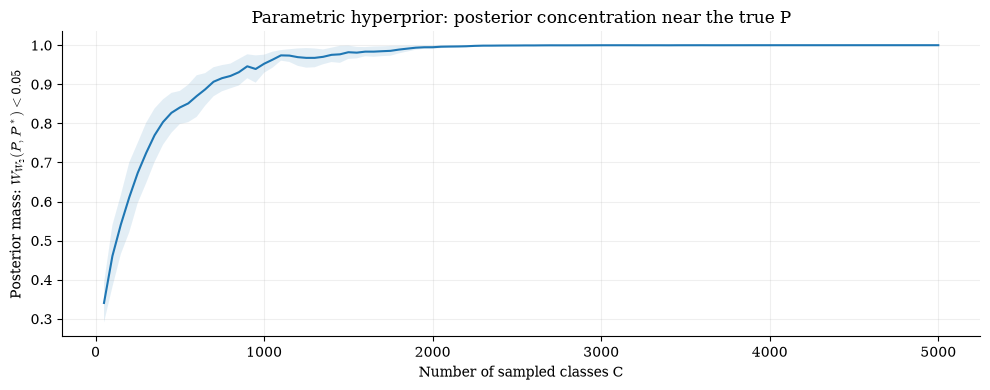

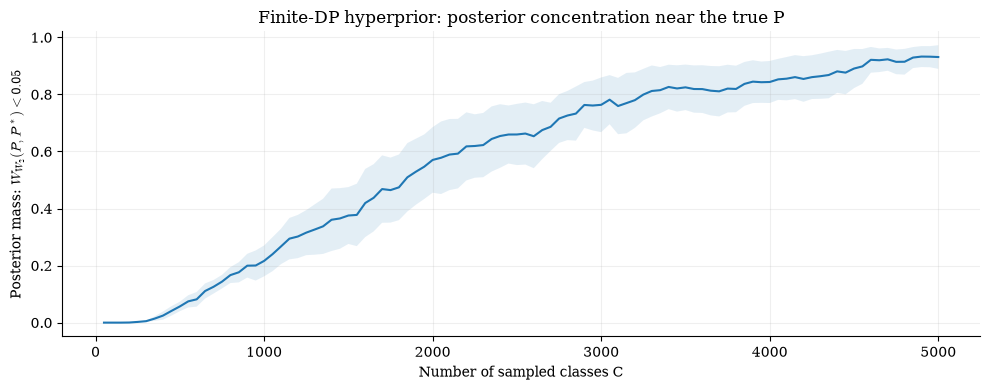

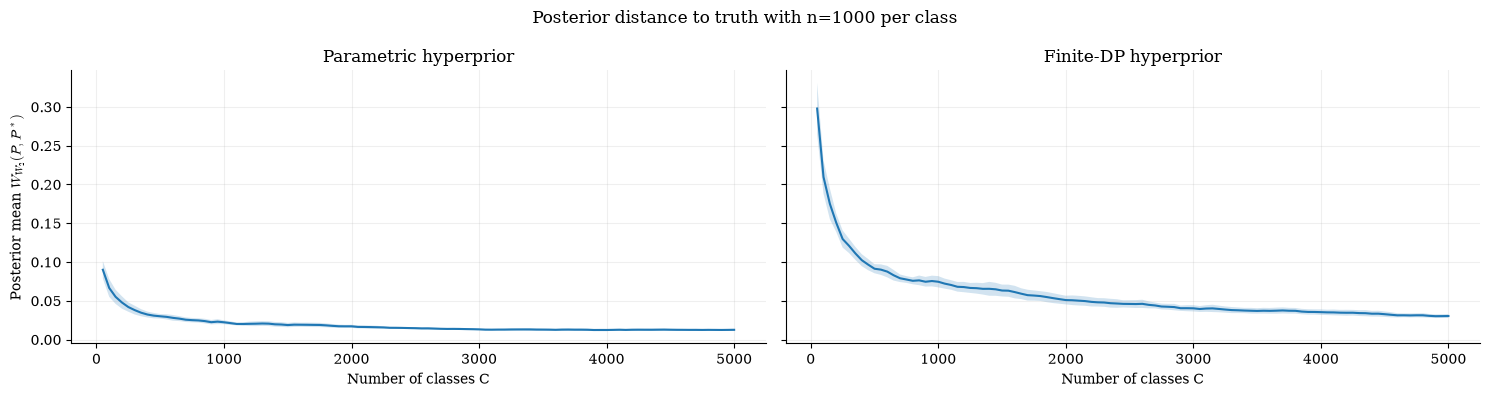

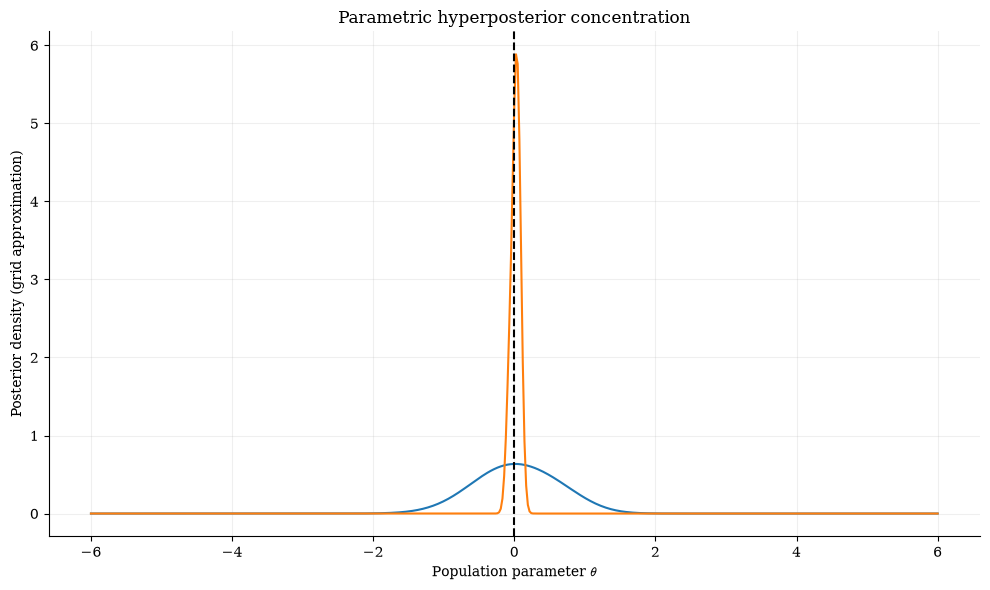

In [8]:
EPS_BY_N, EPS_COMPARE = 0.05, 0.10

res = U.load_bayes_results(U.bayes_dir(cfg))
summ = U.bayes_summaries(res)

U.plot_bayes_mass_by_n(res, summ, "param", EPS_BY_N); plt.show()
U.plot_bayes_mass_by_n(res, summ, "dp", EPS_BY_N); plt.show()
U.plot_bayes_distance(res, summ); plt.show()
U.plot_theta_posterior(res); plt.show()